# HT-9046MX — State-aware Baseline & Relationship Analysis

Notebook นี้วิเคราะห์ข้อมูล Compressor ของ HT-9046MX โดยยึด `README_System.md` และหลักฐานที่พบใน log จริง

เป้าหมาย:

- ตรวจ coverage และคุณภาพข้อมูลของทุกเครื่อง
- แบ่ง operating state โดยไม่ฝืนติดป้าย `Cold / Room / Hot`
- สร้าง baseline แยก `machine × module × SV`
- ตรวจว่า baseline รายเครื่องและรายโมดูลเท่ากันหรือไม่
- วิเคราะห์ความสัมพันธ์ contemporaneous และ lagged response
- สร้างตาราง/กราฟที่ใช้เตรียม Machine Calibration Profile และ ML ในอนาคต

ข้อจำกัดสำคัญ: ไม่มี recipe, setpoint, actual DUT temperature, alarm log หรือ maintenance label จึงไม่สรุป leak หรือชื่อโหมดจาก pressure/SV เพียงตัวเดียว

## tl;dr

ส่วนนี้จะถูกสรุปจากผลลัพธ์ที่รันจริงด้านล่าง โดยหลักการใช้งานคือ:

- `SV=ON` เป็น bypass-active regime ไม่ใช่ชื่อ Room/Hot โดยอัตโนมัติ
- `Status=Stop` ไม่ใช้สร้าง running baseline
- `ChangeValve`, `MValveHome`, `AdjustValve`, `Busy=1` และ `Valve<0` เป็น control sequence
- baseline หลักแยกตามเครื่อง โมดูล และ SV
- ผล correlation เป็นความสัมพันธ์ ไม่ใช่เหตุและผล

## Context & Methods

### 1. Setup and parameters

In [1]:
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

required = {
    "polars": "polars>=1.20",
    "pyarrow": "pyarrow>=15",
    "pandas": "pandas>=2",
    "numpy": "numpy>=1.26",
    "scipy": "scipy>=1.11",
    "matplotlib": "matplotlib>=3.8",
}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import json
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.style.use("seaborn-v0_8-whitegrid")

PROJECT_ROOT = Path(os.environ.get("HT9046MX_PROJECT_ROOT", Path.cwd())).resolve()
DATASET_NAME = "HT9046MX-20260902T013607Z-1-001"
candidate_roots = [
    PROJECT_ROOT / DATASET_NAME / "HT9046MX" / "raw" / "table=ht9046mx_readings",
    PROJECT_ROOT.parent / DATASET_NAME / "HT9046MX" / "raw" / "table=ht9046mx_readings",
    Path("/content/drive/MyDrive") / DATASET_NAME / "HT9046MX" / "raw" / "table=ht9046mx_readings",
]
DATA_ROOT = next((p for p in candidate_roots if p.exists()), candidate_roots[0])
OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "ht9046mx_colab_analysis"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
CACHE_ROOT = OUTPUT_ROOT / "cache"
for folder in (OUTPUT_ROOT, FIGURE_ROOT, CACHE_ROOT):
    folder.mkdir(parents=True, exist_ok=True)

SETTLE_MINUTES = 3
MIN_BASELINE_MINUTES = 120
MIN_CORRELATION_POINTS = 120
LAGS_MINUTES = list(range(0, 11))

METRICS = ["hp1", "lp1", "hp2", "lp2", "valve", "temphi", "templo"]
PRESSURE_METRICS = ["hp1", "lp1", "hp2", "lp2"]
MODULE_NAMES = {
    1: "Index L Arm1", 2: "Index R Arm1", 3: "Index L Arm2", 4: "Index R Arm2",
    5: "SH1", 6: "SH2", 7: "Hot1", 8: "Hot2",
}

print("DATA_ROOT:", DATA_ROOT)
print("OUTPUT_ROOT:", OUTPUT_ROOT)

DATA_ROOT: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\HT9046MX-20260902T013607Z-1-001\HT9046MX\raw\table=ht9046mx_readings
OUTPUT_ROOT: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_colab_analysis


### Key assumptions

- Pressure ใช้หน่วยตาม raw log และจะไม่แปลง psig/psia จนกว่าจะยืนยันหน่วย
- `TempHi`/`TempLo` ใช้ชื่อตาม schema จริง แม้ README จะใช้ `TempHigh`/`TempLow`
- เลือกตัวแทนหนึ่งแถวต่อนาทีเพื่อลดข้อมูลประมาณ 1 วินาทีให้วิเคราะห์ได้ทั้ง fleet
- “steady” หมายถึงอยู่ใน state เดิมอย่างน้อย `SETTLE_MINUTES` นาที ไม่ได้หมายความว่าเครื่อง healthy
- baseline คือ observed operating reference ไม่ใช่ผลยืนยันสุขภาพเครื่อง

## Data

### 2. Discover files and profile coverage

In [2]:
files = sorted(DATA_ROOT.rglob("*.parquet"))
if not files:
    raise FileNotFoundError(
        f"ไม่พบ Parquet ใต้ {DATA_ROOT}. ตั้ง HT9046MX_PROJECT_ROOT หรือแก้ DATA_ROOT ใน cell Setup"
    )

lazy = pl.scan_parquet([str(p) for p in files], hive_partitioning=False)
inventory = (
    lazy.group_by("machine_number")
    .agg(
        pl.len().alias("rows"),
        pl.col("recorded_at").min().alias("start"),
        pl.col("recorded_at").max().alias("end"),
        pl.col("recorded_at").dt.date().n_unique().alias("observed_days"),
    )
    .sort("machine_number")
    .collect()
)
global_status_counts = lazy.group_by("Status").len().sort("len", descending=True).collect()

inventory.write_csv(OUTPUT_ROOT / "machine_inventory.csv")
global_status_counts.write_csv(OUTPUT_ROOT / "global_status_counts.csv")
display(inventory.to_pandas())
display(global_status_counts.to_pandas())
print(f"Parquet files: {len(files):,}")
print(f"Rows: {inventory['rows'].sum():,}")

,machine_number,rows,start,end,observed_days
0,017,1795565,2026-08-06,2026-09-01 14:50:01,23
1,022,1586307,2026-08-06,2026-09-01 14:55:01,22
2,024,1784687,2026-08-06,2026-09-01 15:24:59,23
3,029,2309449,2026-08-04,2026-09-01 15:30:01,29
4,041,2304813,2026-08-04,2026-09-01 15:45:01,29
5,056,679268,2026-08-04,2026-08-12 01:30:03,9
6,057,1974416,2026-08-04,2026-09-01 16:05:01,25
7,058,2302347,2026-08-04,2026-09-01 16:15:01,29
8,063,210848,2026-08-17,2026-08-19 11:40:05,3
9,070,1965939,2026-08-04,2026-09-01 16:35:01,25


,Status,len
0,Run,25504651
1,Stop,654732


Parquet files: 369
Rows: 26,159,383


### 3. Build or load the one-minute module-state cache

In [3]:
CACHE_FILE = CACHE_ROOT / "minute_module_state.parquet"

def build_minute_cache(parquet_files, cache_file):
    parts_dir = CACHE_ROOT / "minute_parts"
    parts_dir.mkdir(parents=True, exist_ok=True)
    selected = ["machine_number", "recorded_at", "Status"]
    for i in range(1, 9):
        selected += [
            f"Hp_1st_{i}", f"Lp_1st_{i}", f"Hp_2nd_{i}", f"Lp_2nd_{i}",
            f"Valve_{i}", f"Status_{i}", f"TempHi_{i}", f"TempLo_{i}", f"SV_{i}", f"Busy_{i}",
        ]

    chunks = []
    part_number = 0
    for index, path in enumerate(parquet_files, start=1):
        wide = pl.read_parquet(path, columns=selected).sort("recorded_at")
        if wide.is_empty():
            continue
        # One representative observation per real clock minute.
        wide = (
            wide.with_columns(pl.col("recorded_at").dt.truncate("1m").alias("minute"))
            .unique(subset=["machine_number", "minute"], keep="last", maintain_order=True)
        )
        module_frames = []
        for module in range(1, 9):
            module_frames.append(
                wide.select(
                    "machine_number", "minute", pl.col("Status").alias("global_status"),
                    pl.lit(module).cast(pl.Int8).alias("module"),
                    pl.col(f"Status_{module}").alias("module_status"),
                    pl.col(f"SV_{module}").alias("sv"),
                    pl.col(f"Busy_{module}").cast(pl.Int8).alias("busy"),
                    pl.col(f"Hp_1st_{module}").cast(pl.Float64).alias("hp1"),
                    pl.col(f"Lp_1st_{module}").cast(pl.Float64).alias("lp1"),
                    pl.col(f"Hp_2nd_{module}").cast(pl.Float64).alias("hp2"),
                    pl.col(f"Lp_2nd_{module}").cast(pl.Float64).alias("lp2"),
                    pl.col(f"Valve_{module}").cast(pl.Float64).alias("valve"),
                    pl.col(f"TempHi_{module}").cast(pl.Float64).alias("temphi"),
                    pl.col(f"TempLo_{module}").cast(pl.Float64).alias("templo"),
                )
            )
        chunks.append(pl.concat(module_frames, how="vertical"))
        if len(chunks) >= 20 or index == len(parquet_files):
            part = pl.concat(chunks, how="vertical")
            part.write_parquet(parts_dir / f"part_{part_number:04d}.parquet", compression="zstd")
            part_number += 1
            chunks = []
        if index % 50 == 0 or index == len(parquet_files):
            print(f"Processed {index:,}/{len(parquet_files):,} files")

    part_files = sorted(parts_dir.glob("part_*.parquet"))
    if not part_files:
        raise RuntimeError("Minute cache build produced no files")
    pl.scan_parquet([str(p) for p in part_files]).sink_parquet(cache_file, compression="zstd")


if not CACHE_FILE.exists():
    build_minute_cache(files, CACHE_FILE)

minute = pl.read_parquet(CACHE_FILE).sort(["machine_number", "module", "minute"])
print(f"Minute-module observations: {minute.height:,}")
display(minute.head(8).to_pandas())

Minute-module observations: 3,548,928


,machine_number,minute,global_status,module,module_status,sv,busy,hp1,lp1,hp2,lp2,valve,temphi,templo
0,017,2026-08-06 00:00:00,Run,1,On,Off,0,157.7,27.0,190.8,13.4,88.0,70.1,-68.1
1,017,2026-08-06 00:01:00,Run,1,On,Off,0,157.8,27.3,191.2,13.3,88.0,70.1,-68.0
2,017,2026-08-06 00:02:00,Run,1,On,Off,0,157.8,27.2,190.8,13.3,88.0,70.2,-68.1
3,017,2026-08-06 00:03:00,Run,1,On,Off,0,157.9,27.2,190.9,13.3,88.0,70.3,-68.0
4,017,2026-08-06 00:04:00,Run,1,On,Off,0,157.8,27.1,190.9,13.3,88.0,70.3,-68.0
5,017,2026-08-06 00:05:00,Run,1,On,Off,0,157.7,26.8,190.5,13.5,88.0,70.3,-68.1
6,017,2026-08-06 00:06:00,Run,1,On,Off,0,157.7,26.9,190.3,13.4,88.0,70.3,-68.1
7,017,2026-08-06 00:07:00,Run,1,On,Off,0,157.8,27.0,190.1,13.3,88.0,70.3,-68.1


### 4. Derive states from fields that actually exist

In [4]:
control_states = ["ChangeValve", "MValveHome", "AdjustValve"]
minute = minute.with_columns(
    pl.when(pl.col("global_status") == "Stop")
    .then(pl.lit("GLOBAL_STOP"))
    .when(
        (pl.col("module_status").is_in(control_states))
        | (pl.col("busy") == 1)
        | (pl.col("valve") < 0)
    )
    .then(pl.lit("CONTROL_SEQUENCE"))
    .when(pl.col("module_status") == "Off")
    .then(pl.lit("RUN_MODULE_OFF"))
    .when(
        (pl.col("global_status") == "Run")
        & (pl.col("module_status") == "On")
        & (pl.col("busy") == 0)
        & (pl.col("valve") >= 0)
        & (pl.col("sv") == "Off")
    )
    .then(pl.lit("RUN_ON_SV_OFF"))
    .when(
        (pl.col("global_status") == "Run")
        & (pl.col("module_status") == "On")
        & (pl.col("busy") == 0)
        & (pl.col("valve") >= 0)
        & (pl.col("sv") == "On")
    )
    .then(pl.lit("RUN_ON_SV_ON"))
    .otherwise(pl.lit("UNCLASSIFIED"))
    .alias("state")
)

minute = minute.with_columns(
    (
        (pl.col("state") != pl.col("state").shift(1).over(["machine_number", "module"]))
        | (pl.col("minute").diff().over(["machine_number", "module"]).dt.total_minutes() > 2)
    ).fill_null(True).alias("segment_start")
).with_columns(
    pl.col("segment_start").cast(pl.Int64).cum_sum().over(["machine_number", "module"]).alias("segment_id")
).with_columns(
    pl.col("minute").cum_count().over(["machine_number", "module", "segment_id"]).alias("minutes_in_state")
)

minute = minute.with_columns(
    (
        pl.col("state").is_in(["RUN_ON_SV_OFF", "RUN_ON_SV_ON"])
        & (pl.col("minutes_in_state") >= SETTLE_MINUTES)
    ).alias("baseline_eligible")
)

state_counts = (
    minute.group_by(["machine_number", "module", "state"])
    .len().rename({"len": "minutes"})
    .sort(["machine_number", "module", "minutes"], descending=[False, False, True])
)
state_counts.write_csv(OUTPUT_ROOT / "state_counts.csv")
display(state_counts.head(30).to_pandas())

,machine_number,module,state,minutes
0,017,1,RUN_ON_SV_OFF,27441
1,017,1,RUN_MODULE_OFF,1870
2,017,1,RUN_ON_SV_ON,627
3,017,1,GLOBAL_STOP,324
4,017,1,CONTROL_SEQUENCE,178
5,017,2,RUN_ON_SV_OFF,27486
6,017,2,RUN_MODULE_OFF,1846
7,017,2,RUN_ON_SV_ON,632
8,017,2,GLOBAL_STOP,324
9,017,2,CONTROL_SEQUENCE,152


## Results

### 5. Data coverage and state composition

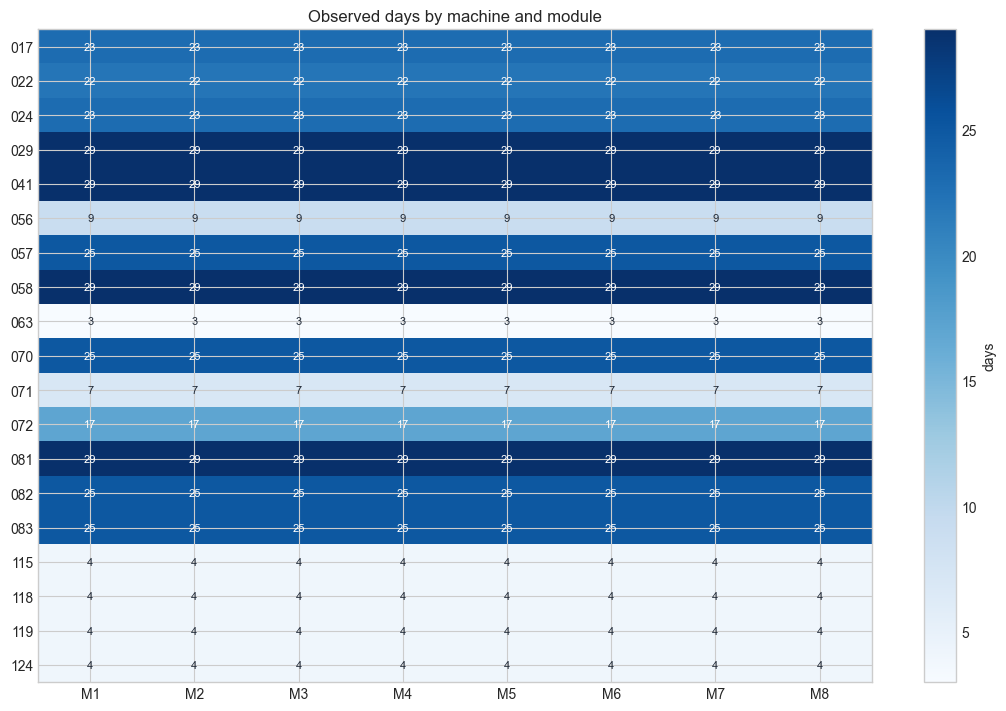

In [5]:
coverage = (
    minute.group_by(["machine_number", "module"])
    .agg(
        pl.len().alias("observed_minutes"),
        pl.col("minute").dt.date().n_unique().alias("observed_days"),
        pl.col("baseline_eligible").sum().alias("baseline_minutes"),
        pl.col("minute").filter(pl.col("baseline_eligible")).dt.date().n_unique().alias("baseline_days"),
        (pl.col("state") == "CONTROL_SEQUENCE").sum().alias("control_minutes"),
        (pl.col("state") == "GLOBAL_STOP").sum().alias("stop_minutes"),
    )
    .with_columns(
        (100 * pl.col("baseline_minutes") / pl.col("observed_minutes")).alias("baseline_pct")
    )
    .sort(["machine_number", "module"])
)
coverage.write_csv(OUTPUT_ROOT / "module_coverage.csv")

coverage_pdf = coverage.to_pandas()
pivot = coverage_pdf.pivot(index="machine_number", columns="module", values="observed_days")
fig, ax = plt.subplots(figsize=(11, max(5, 0.38 * len(pivot))))
im = ax.imshow(pivot.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(8), [f"M{i}" for i in range(1, 9)])
ax.set_yticks(range(len(pivot)), pivot.index)
ax.set_title("Observed days by machine and module")
for y in range(len(pivot)):
    for x in range(8):
        value = pivot.iloc[y, x]
        ax.text(x, y, f"{value:.0f}", ha="center", va="center", fontsize=8,
                color="white" if value > np.nanmax(pivot.values) * 0.55 else "#1f2937")
fig.colorbar(im, ax=ax, label="days")
fig.tight_layout()
fig.savefig(FIGURE_ROOT / "01_coverage_days.png", dpi=160, bbox_inches="tight")
plt.show()

### 6. Baseline profiles: machine × module × SV

In [6]:
eligible = minute.filter(pl.col("baseline_eligible"))
quantile_exprs = []
for metric in METRICS:
    quantile_exprs += [
        pl.col(metric).median().alias(f"{metric}_median"),
        pl.col(metric).quantile(0.25).alias(f"{metric}_q25"),
        pl.col(metric).quantile(0.75).alias(f"{metric}_q75"),
        pl.col(metric).quantile(0.05).alias(f"{metric}_q05"),
        pl.col(metric).quantile(0.95).alias(f"{metric}_q95"),
    ]

baseline = (
    eligible.group_by(["machine_number", "module", "sv"])
    .agg(
        pl.len().alias("n_minutes"),
        pl.col("minute").dt.date().n_unique().alias("n_days"),
        *quantile_exprs,
    )
    .with_columns((pl.col("n_minutes") >= MIN_BASELINE_MINUTES).alias("sufficient_baseline"))
    .sort(["machine_number", "module", "sv"])
)
baseline.write_csv(OUTPUT_ROOT / "baseline_stats.csv")
display(baseline.head(24).to_pandas())

,machine_number,module,sv,n_minutes,n_days,hp1_median,hp1_q25,hp1_q75,hp1_q05,hp1_q95,...,temphi_q25,temphi_q75,temphi_q05,temphi_q95,templo_median,templo_q25,templo_q75,templo_q05,templo_q95,sufficient_baseline
0,017,1,Off,27352,21,158.50,157.4,159.1,155.3,159.9,...,59.5,63.5,57.4,80.4,-66.8,-67.2,-66.3,-67.9,-50.9,True
1,017,1,On,593,9,162.90,161.4,166.0,157.7,169.1,...,-0.4,78.2,-1.4,112.1,-63.1,-63.7,-21.9,-63.9,12.1,True
2,017,2,Off,27400,21,158.10,157.6,158.7,157.0,159.7,...,73.4,77.0,71.8,79.7,-66.0,-66.5,-65.6,-67.0,-55.7,True
3,017,2,On,596,9,164.40,161.9,170.0,157.3,189.9,...,7.5,88.1,5.7,106.6,-63.1,-64.2,-20.0,-64.6,11.0,True
4,017,3,Off,27386,21,160.20,159.1,161.5,157.8,162.6,...,80.6,85.4,79.1,91.0,-50.6,-57.9,-45.5,-62.1,-31.7,True
5,017,3,On,604,9,163.95,163.1,165.0,161.6,170.7,...,19.2,86.8,17.1,105.4,-64.4,-65.0,-36.2,-65.2,13.0,True
6,017,4,Off,27396,21,158.00,156.9,159.0,155.7,160.6,...,65.2,70.8,62.1,82.4,-66.5,-66.8,-65.9,-67.2,-65.1,True
7,017,4,On,2268,12,160.20,159.6,161.5,157.7,180.3,...,65.1,67.6,20.0,100.7,-64.0,-64.2,-63.8,-64.4,-3.3,True
8,017,5,Off,27422,21,159.30,158.4,160.2,156.5,162.0,...,64.0,67.7,61.5,76.0,-64.9,-65.2,-64.8,-65.8,-63.8,True
9,017,5,On,280,9,160.90,160.6,183.5,158.7,190.4,...,67.1,89.9,65.1,105.7,-63.3,-63.9,-11.2,-64.5,18.0,True


### 7. Are fleet baselines equal? Compare between-machine shifts with within-machine IQR

,sv,module,metric,machines,fleet_median,between_machine_iqr,typical_within_machine_iqr,between_to_within_ratio,interpretation
81,On,4,valve,12,80.50,12.0000,0.50,24.000000,machine calibration strongly indicated
69,On,2,templo,11,-62.50,12.6500,0.70,18.071429,machine calibration strongly indicated
83,On,4,templo,12,-62.50,12.9250,0.95,13.605263,machine calibration strongly indicated
63,On,2,hp1,11,157.00,14.8000,1.10,13.454545,machine calibration strongly indicated
97,On,6,templo,10,-58.30,53.3750,4.10,13.018293,machine calibration strongly indicated
40,Off,6,temphi,19,91.80,13.0500,1.20,10.875000,machine calibration strongly indicated
62,On,1,templo,12,-58.95,26.4000,2.55,10.352941,machine calibration strongly indicated
75,On,3,temphi,12,74.25,69.9375,6.85,10.209854,machine calibration strongly indicated
33,Off,5,temphi,19,85.80,15.5000,1.60,9.687500,machine calibration strongly indicated
7,Off,2,hp1,19,145.80,10.6000,1.10,9.636364,machine calibration strongly indicated


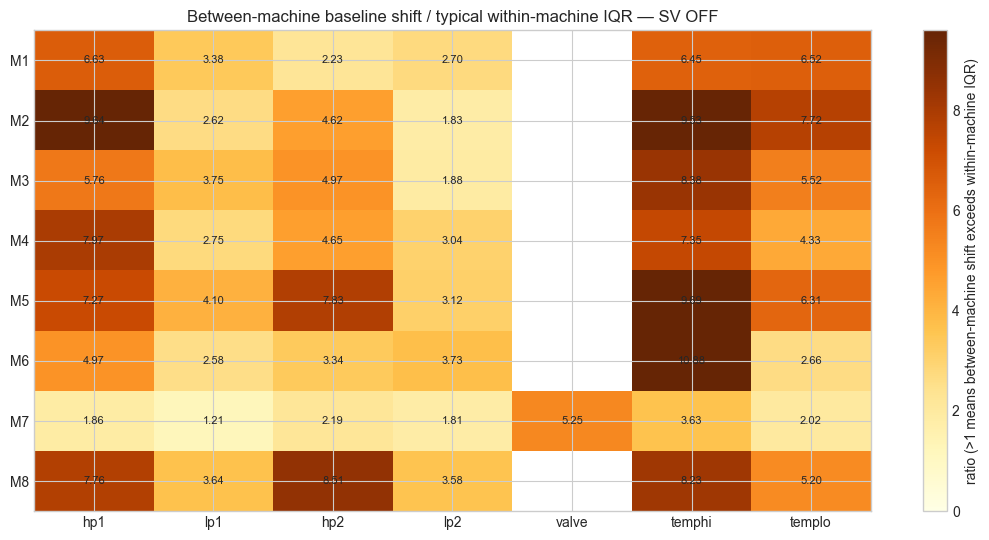

In [7]:
rows = []
baseline_pdf = baseline.filter(pl.col("sufficient_baseline")).to_pandas()
for sv in sorted(baseline_pdf["sv"].dropna().unique()):
    for module in range(1, 9):
        subset = baseline_pdf[(baseline_pdf["sv"] == sv) & (baseline_pdf["module"] == module)]
        for metric in METRICS:
            medians = subset[f"{metric}_median"].dropna().astype(float)
            within_iqr = (subset[f"{metric}_q75"] - subset[f"{metric}_q25"]).dropna().astype(float)
            if len(medians) < 3:
                continue
            between_iqr = float(medians.quantile(0.75) - medians.quantile(0.25))
            typical_within_iqr = float(within_iqr.median()) if len(within_iqr) else np.nan
            ratio = between_iqr / typical_within_iqr if typical_within_iqr > 0 else np.nan
            rows.append({
                "sv": sv, "module": module, "metric": metric,
                "machines": len(medians),
                "fleet_median": float(medians.median()),
                "between_machine_iqr": between_iqr,
                "typical_within_machine_iqr": typical_within_iqr,
                "between_to_within_ratio": ratio,
            })

comparability = pd.DataFrame(rows)
comparability["interpretation"] = np.select(
    [
        comparability["between_to_within_ratio"] >= 1.0,
        comparability["between_to_within_ratio"] >= 0.5,
    ],
    ["machine calibration strongly indicated", "machine calibration likely useful"],
    default="more transferable, still validate",
)
comparability.to_csv(OUTPUT_ROOT / "baseline_comparability.csv", index=False)
display(comparability.sort_values("between_to_within_ratio", ascending=False).head(30))

sv_off_cmp = comparability[comparability["sv"] == "Off"]
heat = sv_off_cmp.pivot(index="module", columns="metric", values="between_to_within_ratio").reindex(columns=METRICS)
fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(heat.values, aspect="auto", cmap="YlOrBr", vmin=0,
               vmax=max(1.5, np.nanpercentile(heat.values, 95)))
ax.set_xticks(range(len(METRICS)), METRICS)
ax.set_yticks(range(8), [f"M{i}" for i in range(1, 9)])
ax.set_title("Between-machine baseline shift / typical within-machine IQR — SV OFF")
for y in range(heat.shape[0]):
    for x in range(heat.shape[1]):
        value = heat.iloc[y, x]
        if pd.notna(value):
            ax.text(x, y, f"{value:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="ratio (>1 means between-machine shift exceeds within-machine IQR)")
fig.tight_layout()
fig.savefig(FIGURE_ROOT / "02_baseline_comparability_sv_off.png", dpi=170, bbox_inches="tight")
plt.show()

### 8. Per-machine baseline deviation maps

In [8]:
def robust_z(values):
    values = np.asarray(values, dtype=float)
    center = np.nanmedian(values)
    mad = np.nanmedian(np.abs(values - center))
    if not np.isfinite(mad) or mad == 0:
        return np.zeros_like(values)
    return 0.67448975 * (values - center) / mad

sv_off = baseline_pdf[(baseline_pdf["sv"] == "Off") & baseline_pdf["sufficient_baseline"]].copy()
for metric in METRICS:
    sv_off[f"{metric}_fleet_rz"] = sv_off.groupby("module")[f"{metric}_median"].transform(robust_z)

for machine in sorted(sv_off["machine_number"].unique()):
    machine_df = sv_off[sv_off["machine_number"] == machine].set_index("module")
    matrix = machine_df.reindex(range(1, 9))[[f"{m}_fleet_rz" for m in METRICS]].to_numpy(float)
    fig, ax = plt.subplots(figsize=(11, 5.5))
    im = ax.imshow(matrix, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
    ax.set_xticks(range(len(METRICS)), METRICS)
    ax.set_yticks(range(8), [f"M{i} {MODULE_NAMES[i]}" for i in range(1, 9)])
    ax.set_title(f"Machine {machine}: baseline median vs fleet peers — SV OFF")
    for y in range(8):
        for x in range(len(METRICS)):
            value = matrix[y, x]
            if np.isfinite(value):
                ax.text(x, y, f"{value:+.1f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, label="robust z-score versus same module across machines")
    fig.tight_layout()
    fig.savefig(FIGURE_ROOT / f"machine_{machine}_baseline_map.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

print(f"Saved {sv_off['machine_number'].nunique()} machine baseline maps")

Saved 19 machine baseline maps


### 9. Spearman relationships per machine and module

In [9]:
correlation_rows = []
eligible_groups = eligible.partition_by(["machine_number", "module", "sv"], as_dict=True)
pair_names = [(METRICS[a], METRICS[b]) for a in range(len(METRICS)) for b in range(a + 1, len(METRICS))]

for key, group in eligible_groups.items():
    machine, module, sv = key
    pdf = group.select(METRICS).to_pandas().replace([np.inf, -np.inf], np.nan)
    if len(pdf) < MIN_CORRELATION_POINTS:
        continue
    corr = pdf.corr(method="spearman", min_periods=MIN_CORRELATION_POINTS)
    for left, right in pair_names:
        value = corr.loc[left, right]
        if pd.notna(value):
            correlation_rows.append({
                "machine_number": machine, "module": int(module), "sv": sv,
                "feature_x": left, "feature_y": right,
                "spearman_rho": float(value), "n_minutes": len(pdf),
            })

correlations = pd.DataFrame(correlation_rows)
correlations.to_csv(OUTPUT_ROOT / "spearman_correlations.csv", index=False)
display(correlations.reindex(correlations.spearman_rho.abs().sort_values(ascending=False).index).head(30))

,machine_number,module,sv,feature_x,feature_y,spearman_rho,n_minutes
1649,057,6,On,temphi,templo,0.996564,145
2496,071,8,Off,lp1,hp2,0.988529,6342
2278,070,5,On,lp2,temphi,0.988212,317
1341,056,5,Off,lp1,hp2,0.986941,11395
3819,118,8,Off,lp1,hp2,0.985365,4866
3824,118,8,Off,hp2,lp2,0.985165,4866
305,022,1,Off,hp2,lp2,0.983737,22880
3882,119,3,Off,lp1,hp2,0.981743,3157
3945,119,6,Off,lp1,hp2,0.981233,3157
3777,118,5,Off,lp1,hp2,0.980018,4866


### 10. Per-machine correlation maps — SV OFF

In [10]:
for machine in sorted(correlations["machine_number"].unique()):
    fig, axes = plt.subplots(2, 4, figsize=(18, 9), constrained_layout=True)
    for module, ax in zip(range(1, 9), axes.flat):
        subset = correlations[
            (correlations["machine_number"] == machine)
            & (correlations["module"] == module)
            & (correlations["sv"] == "Off")
        ]
        matrix = pd.DataFrame(np.eye(len(METRICS)), index=METRICS, columns=METRICS)
        for row in subset.itertuples():
            matrix.loc[row.feature_x, row.feature_y] = row.spearman_rho
            matrix.loc[row.feature_y, row.feature_x] = row.spearman_rho
        im = ax.imshow(matrix.values, cmap="coolwarm", vmin=-1, vmax=1)
        ax.set_xticks(range(len(METRICS)), METRICS, rotation=45, ha="right", fontsize=7)
        ax.set_yticks(range(len(METRICS)), METRICS, fontsize=7)
        ax.set_title(f"M{module} {MODULE_NAMES[module]}", fontsize=10)
    fig.suptitle(f"Machine {machine}: Spearman relationships by module — steady SV OFF", fontsize=15)
    fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7, label="Spearman rho")
    fig.savefig(FIGURE_ROOT / f"machine_{machine}_correlations.png", dpi=145, bbox_inches="tight")
    plt.close(fig)

print("Saved per-machine correlation maps")

Saved per-machine correlation maps


### 11. Lag response: Valve(t) versus pressure/temperature(t + lag)

,machine_number,module,target,relationship_type,lag_minutes,spearman_rho,n_pairs,abs_rho
1077,124,3,temphi,level,0,-0.915097,1083,0.915097
341,056,8,temphi,level,0,0.864857,11395,0.864857
71,022,2,templo,level,0,-0.847209,22838,0.847209
111,022,8,templo,level,0,-0.833523,22862,0.833523
107,022,8,lp2,level,1,0.822189,22861,0.822189
1033,119,6,hp2,level,0,-0.816490,3157,0.816490
73,022,3,hp2,level,10,-0.807764,22860,0.807764
1059,124,1,lp2,level,9,0.803530,1075,0.803530
105,022,8,hp2,level,0,0.793609,22862,0.793609
77,022,3,temphi,level,0,0.786387,22870,0.786387


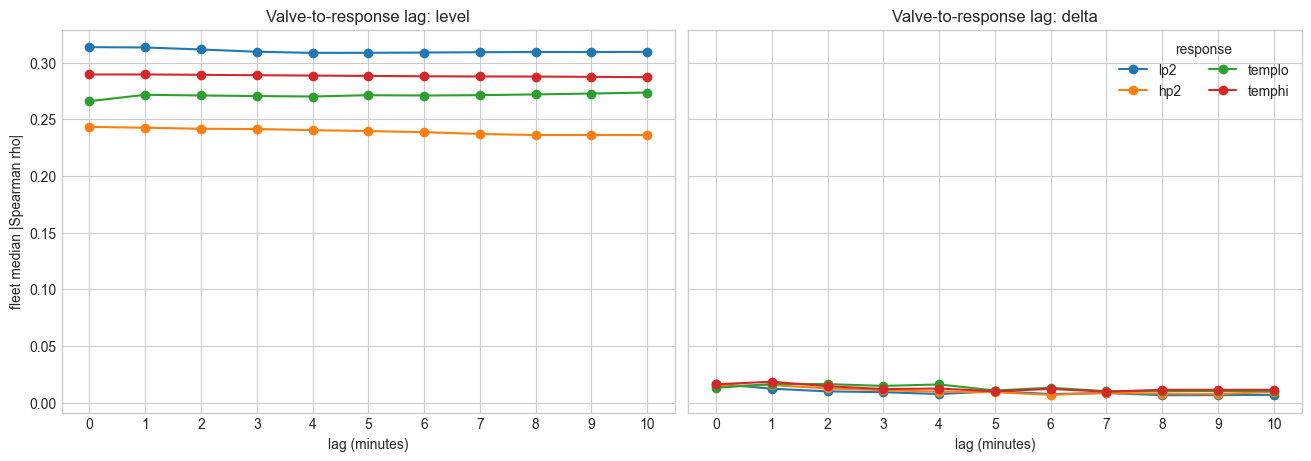

In [11]:
lag_rows = []
sv_off_groups = eligible.filter(pl.col("sv") == "Off").partition_by(
    ["machine_number", "module"], as_dict=True
)
targets = ["lp2", "hp2", "templo", "temphi"]

for key, group in sv_off_groups.items():
    machine, module = key
    pdf = group.select(["minute", "valve", *targets]).sort("minute").to_pandas()
    if len(pdf) < MIN_CORRELATION_POINTS:
        continue
    for lag in LAGS_MINUTES:
        for target in targets:
            for relationship_type, driver, response in [
                ("level", pdf["valve"], pdf[target]),
                ("delta", pdf["valve"].diff(), pdf[target].diff()),
            ]:
                aligned = pd.concat([driver, response.shift(-lag)], axis=1).dropna()
                if len(aligned) < MIN_CORRELATION_POINTS:
                    continue
                rho = aligned.corr(method="spearman").iloc[0, 1]
                lag_rows.append({
                    "machine_number": machine, "module": int(module), "lag_minutes": lag,
                    "target": target, "relationship_type": relationship_type,
                    "spearman_rho": float(rho), "n_pairs": len(aligned),
                })

lag_relationships = pd.DataFrame(lag_rows)
lag_relationships.to_csv(OUTPUT_ROOT / "lag_relationships.csv", index=False)

best_lags = (
    lag_relationships.assign(abs_rho=lambda d: d.spearman_rho.abs())
    .sort_values("abs_rho", ascending=False)
    .groupby(["machine_number", "module", "target", "relationship_type"], as_index=False)
    .first()
)
best_lags.to_csv(OUTPUT_ROOT / "best_lag_relationships.csv", index=False)
display(best_lags.sort_values("abs_rho", ascending=False).head(30))

fleet_lag = (
    lag_relationships.assign(abs_rho=lambda d: d.spearman_rho.abs())
    .groupby(["relationship_type", "target", "lag_minutes"], as_index=False)
    .agg(median_abs_rho=("abs_rho", "median"))
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, constrained_layout=True)
for relationship_type, ax in zip(["level", "delta"], axes):
    for target in targets:
        part = fleet_lag[
            (fleet_lag["relationship_type"] == relationship_type)
            & (fleet_lag["target"] == target)
        ]
        ax.plot(part["lag_minutes"], part["median_abs_rho"], marker="o", label=target)
    ax.set_title(f"Valve-to-response lag: {relationship_type}")
    ax.set_xlabel("lag (minutes)")
    ax.set_xticks(LAGS_MINUTES)
axes[0].set_ylabel("fleet median |Spearman rho|")
axes[1].legend(title="response", ncol=2)
fig.savefig(FIGURE_ROOT / "03_valve_response_lags.png", dpi=170, bbox_inches="tight")
plt.show()

### 12. Daily trends for every machine and module

In [12]:
daily = (
    eligible.filter(pl.col("sv") == "Off")
    .with_columns(pl.col("minute").dt.date().alias("date"))
    .group_by(["machine_number", "module", "date"])
    .agg(
        pl.len().alias("n_minutes"),
        pl.col("hp2").median().alias("hp2_median"),
        pl.col("lp2").median().alias("lp2_median"),
        pl.col("valve").median().alias("valve_median"),
    )
    .sort(["machine_number", "module", "date"])
)
daily.write_csv(OUTPUT_ROOT / "daily_baseline_trends.csv")

daily_pdf = daily.to_pandas()
for machine in sorted(daily_pdf["machine_number"].unique()):
    part = daily_pdf[daily_pdf["machine_number"] == machine]
    fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True, constrained_layout=True)
    for module in range(1, 9):
        m = part[part["module"] == module]
        if m.empty:
            continue
        axes[0].plot(m["date"], m["hp2_median"], marker="o", ms=2.5, lw=1, label=f"M{module}")
        axes[1].plot(m["date"], m["lp2_median"], marker="o", ms=2.5, lw=1)
        axes[2].plot(m["date"], m["valve_median"], marker="o", ms=2.5, lw=1)
    axes[0].set_title(f"Machine {machine}: daily steady baseline — SV OFF")
    axes[0].set_ylabel("Hp_2nd median")
    axes[1].set_ylabel("Lp_2nd median")
    axes[2].set_ylabel("Valve median")
    axes[2].set_xlabel("Date")
    axes[0].legend(ncol=8, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.22))
    for ax in axes:
        ax.tick_params(axis="x", rotation=45)
    fig.savefig(FIGURE_ROOT / f"machine_{machine}_daily_trends.png", dpi=145, bbox_inches="tight")
    plt.close(fig)

print("Saved per-machine daily trend charts")

Saved per-machine daily trend charts


## Takeaways

### 13. Generate an ML-readiness summary from executed evidence

In [13]:
module_readiness = coverage.with_columns(
    pl.when(
        (pl.col("baseline_days") >= 14)
        & (pl.col("baseline_minutes") >= MIN_BASELINE_MINUTES)
    ).then(pl.lit("candidate for calibration"))
    .when(pl.col("baseline_minutes") >= MIN_BASELINE_MINUTES)
    .then(pl.lit("short-history calibration only"))
    .otherwise(pl.lit("insufficient baseline"))
    .alias("ml_readiness")
)
module_readiness.write_csv(OUTPUT_ROOT / "machine_module_ml_readiness.csv")

machine_readiness = (
    module_readiness.group_by("machine_number")
    .agg(
        (pl.col("ml_readiness") == "candidate for calibration").sum().alias("candidate_modules"),
        (pl.col("ml_readiness") == "short-history calibration only").sum().alias("short_history_modules"),
        (pl.col("ml_readiness") == "insufficient baseline").sum().alias("insufficient_modules"),
        pl.col("baseline_minutes").median().alias("median_module_baseline_minutes"),
    )
    .sort("machine_number")
)
machine_readiness.write_csv(OUTPUT_ROOT / "machine_ml_readiness.csv")
display(machine_readiness.to_pandas())
display(module_readiness.filter(pl.col("ml_readiness") != "candidate for calibration").to_pandas())

summary = {
    "parquet_files": len(files),
    "raw_rows": int(inventory["rows"].sum()),
    "machines": int(inventory.height),
    "date_start": str(inventory["start"].min()),
    "date_end": str(inventory["end"].max()),
    "minute_module_rows": int(minute.height),
    "baseline_eligible_rows": int(eligible.height),
    "candidate_machine_module_profiles": int(
        module_readiness.filter(pl.col("ml_readiness") == "candidate for calibration").height
    ),
    "machines_with_at_least_6_candidate_modules": int(
        machine_readiness.filter(pl.col("candidate_modules") >= 6).height
    ),
    "highest_between_to_within_ratio": float(comparability["between_to_within_ratio"].max()),
    "median_between_to_within_ratio": float(comparability["between_to_within_ratio"].median()),
}
(OUTPUT_ROOT / "analysis_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(summary, ensure_ascii=False, indent=2))

print("\nInterpretation")
print("- Absolute baselines should not be pooled when between/within ratio is large.")
print("- Prefer shared relative/response features plus machine-module calibration profiles.")
print("- Keep SV ON and OFF as separate regimes.")
print("- Treat correlations and lags as screening evidence, not causal proof.")
print("- Leak classification still requires maintenance outcomes or verified event labels.")

,machine_number,candidate_modules,short_history_modules,insufficient_modules,median_module_baseline_minutes
0,017,7,0,1,27823.5
1,022,7,0,1,23950.0
2,024,7,0,1,17376.0
3,029,7,0,1,29425.0
4,041,8,0,0,34854.5
5,056,0,7,1,11467.0
6,057,7,0,1,25927.0
7,058,8,0,0,37311.5
8,063,0,7,1,272.0
9,070,7,0,1,31177.5


,machine_number,module,observed_minutes,observed_days,baseline_minutes,baseline_days,control_minutes,stop_minutes,baseline_pct,ml_readiness
0,017,7,30440,23,0,0,3,324,0.000000,insufficient baseline
1,022,7,26965,22,11,2,74,1777,0.040794,insufficient baseline
2,024,7,30217,23,116,1,41,1508,0.383890,insufficient baseline
3,029,7,39092,29,0,0,2,1087,0.000000,insufficient baseline
4,056,1,11509,9,11467,9,0,8,99.635068,short-history calibration only
...,...,...,...,...,...,...,...,...,...,...
60,124,4,4863,4,3653,4,50,0,75.118240,short-history calibration only
61,124,5,4863,4,4110,4,58,0,84.515731,short-history calibration only
62,124,6,4863,4,4109,4,59,0,84.495168,short-history calibration only
63,124,7,4863,4,0,0,0,0,0.000000,insufficient baseline


{
  "parquet_files": 369,
  "raw_rows": 26159383,
  "machines": 19,
  "date_start": "2026-08-04 00:00:00",
  "date_end": "2026-09-01 17:10:01",
  "minute_module_rows": 3548928,
  "baseline_eligible_rows": 2667008,
  "candidate_machine_module_profiles": 87,
  "machines_with_at_least_6_candidate_modules": 12,
  "highest_between_to_within_ratio": 24.0,
  "median_between_to_within_ratio": 4.640350877192985
}

Interpretation
- Absolute baselines should not be pooled when between/within ratio is large.
- Prefer shared relative/response features plus machine-module calibration profiles.
- Keep SV ON and OFF as separate regimes.
- Treat correlations and lags as screening evidence, not causal proof.
- Leak classification still requires maintenance outcomes or verified event labels.


### Recommended next ML step

1. ใช้ `baseline_stats.csv` สร้าง calibration profile รายเครื่อง–รายโมดูล–ราย SV
2. ใช้ relative features เช่น robust z-score, rolling slope, pressure differential และ lag response
3. แบ่ง validation ตามเวลาและทำ leave-one-machine-out
4. เริ่มด้วย anomaly detection/shadow mode ก่อน supervised leak classification
5. เติม maintenance/service labels แล้วจึงประเมิน precision, recall และ lead time

ผลลัพธ์ทั้งหมดอยู่ใน `outputs/ht9046mx_colab_analysis/`